# Chapter 4: Reading the Result: P-values, Chance to Win and Expected Loss

This notebook runs every piece of code in the chapter, in order, with the chapter's text around it. Read the chapter on the site: [Reading the Result: P-values, Chance to Win and Expected Loss](https://books.sugiv.fyi/lift/reading-result.html). Everything is simulated from seeded code in `sim/`, so a run gives the same numbers as the book.

In [1]:
# Run this cell first. In Google Colab it fetches the companion repo; anywhere else, run the
# notebook from a clone of it. Either way it moves to the repo's root so `sim` can be imported.
import os
import pathlib
import sys

if "google.colab" in sys.modules:
    if not pathlib.Path("/content/lift-not-luck").exists():
        !git clone -q --depth 1 https://github.com/sugix/lift-not-luck /content/lift-not-luck
    %pip install -q pingouin
candidates = [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path("/content/lift-not-luck")]
root = next(p for p in candidates if (p / "sim" / "parlo.py").is_file())
os.chdir(root)
sys.path.insert(0, str(root))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pingouin as pg
from scipy import stats
def glue(name, value, display=True):
    """In the book, glue() puts a computed number into the text. Here the numbers are already
    written into the text, so it only shows the value when asked to."""
    if display:
        from IPython.display import display as show
        show(value)

from sim import readout as R, style

style.apply()
pd.set_option("display.precision", 3)


def glue_num(name, value):
    glue(name, float(value), display=False)


lite = R.juno_lite_test()
lv, lse = lite["value"]
glue_num("lite_gain", 1000 * lv)
glue_num("lite_p", 2 * stats.norm.sf(abs(lv) / lse))
lite_draws = np.random.default_rng(0).normal(lv, lse, 200_000) * 1000
lite_cl = R.chance_and_loss(lite_draws)
glue_num("lite_win", 100 * lite_cl["chance to win"])
glue_num("lite_loss_ship", lite_cl["expected loss if we ship"])
glue_num("lite_loss_keep", lite_cl["expected loss if we don't"])
glue_num("lite_loss_ratio", lite_cl["expected loss if we don't"] / lite_cl["expected loss if we ship"])

Here's the finding first. Juno's team tested **Juno-Lite**, a cheaper model that tutors slightly worse. On value per lesson it came out ahead by **\$2.51 per 1,000 lessons, with p = 0.15**. Not significant. The usual reading is "inconclusive, keep testing" or "no difference, don't bother". Both miss the point.

The decision question is different: *if we switch and we're wrong, how much do we lose?* Averaging over everything the data still allows, and counting zero whenever the choice turns out right, switching has an expected loss of **\$0.06 per 1,000 lessons**. Staying put has an expected loss of **\$2.57**. On value alone, the switch is an easy call, significant or not. (One promise made to learners still stands in the way, as we'll see.)

A p-value, a chance to win and an expected loss answer three different questions. This chapter reads one result all three ways, shows when each is the right tool, and ends with a trap that catches even careful teams: **the tests that win overstate how much they won.**

> **Note**
>
> The numbers come from `lift/sim/readout.py`: Streak Shield's test from Chapters 1 to 3, now clean and properly sized; Juno-Lite against Juno's current medium model (Chapter 7 compares Juno's models in detail); and a simulated history of 2,000 Parlo experiments.

## Reading 1: the p-value and the confidence interval

Streak Shield's test is finally clean: 15,700 learners per arm, sized in Chapter 2, checked in Chapter 3. Here's the frequentist readout:

In [3]:
S = R.streak_clean()
shield, control = S.retained[S.arm == "shield"], S.retained[S.arm == "control"]
diff = shield.mean() - control.mean()
se = np.sqrt(shield.var() / len(shield) + control.var() / len(control))
res = pg.ttest(shield, control)
print(f"lift {100 * diff:.2f} points, 95% CI {100 * (diff - 1.96 * se):.2f} to "
      f"{100 * (diff + 1.96 * se):.2f}, p = {res.p_val.iloc[0]:.4f}")

lift 1.68 points, 95% CI 0.60 to 2.75, p = 0.0023


In [4]:
glue_num("ss_lift", 100 * diff)
glue_num("ss_lo", 100 * (diff - 1.96 * se))
glue_num("ss_hi", 100 * (diff + 1.96 * se))
glue_num("ss_p", res.p_val.iloc[0])
glue_num("ss_true", 100 * S.true_effect.mean())

A lift of 1.7 points, 95% CI 0.6 to 2.8, p = 0.002. (The simulator knows the truth: 1.5.)

What these numbers mean is narrower than most people think:

- **The p-value** is the chance of seeing a difference at least this far from zero, in either direction, *if Streak Shield did nothing*. It is **not** the chance that Streak Shield does nothing, and it is not the chance the result is a fluke.
- **The 95% confidence interval** comes from a procedure that captures the true lift in 95% of experiments. It is a statement about the procedure. Strictly, it isn't "a 95% chance the lift is in this range", though with no prior information the two readings almost coincide, as we're about to see.

These are good tools for one job: **controlling false alarms across many decisions.** If every test ships only at p < 0.05, then at most about 5% of changes that do nothing get shipped. That's a useful guarantee for a platform, and it's why the frequentist readout is the default. It just doesn't answer the question a product manager actually asks.

## Reading 2: chance to win

The question a product manager asks is *"how likely is it that Streak Shield is better?"* That's a Bayesian question, and the machinery is small. Give each arm's retention rate a Beta posterior: start from a flat Beta(1, 1), add the number retained to the first parameter and the number who left to the second. Draw from both posteriors and compare. (Chapter 7 reuses exactly this to build Thompson sampling.)

In [5]:
post = R.beta_posteriors([shield.sum(), control.sum()], [len(shield), len(control)])
lift_draws = 100 * (post[:, 0] - post[:, 1])           # in points
cl = R.chance_and_loss(lift_draws)
print(f"chance Streak Shield is better: {cl['chance to win']:.1%}")
print(f"95% credible interval: {np.percentile(lift_draws, 2.5):.2f} to {np.percentile(lift_draws, 97.5):.2f} points")

chance Streak Shield is better: 99.9%
95% credible interval: 0.60 to 2.75 points


In [6]:
glue_num("ss_win", 100 * cl["chance to win"])
glue_num("ss_loss_ship", cl["expected loss if we ship"])

A 99.9% chance that Streak Shield is better. The credible interval matches the confidence interval to two decimals. With a flat prior and this much data, the two schools agree on the numbers. They disagree only on the words, and the Bayesian words are the ones people use anyway.

Here's the posterior as a picture:

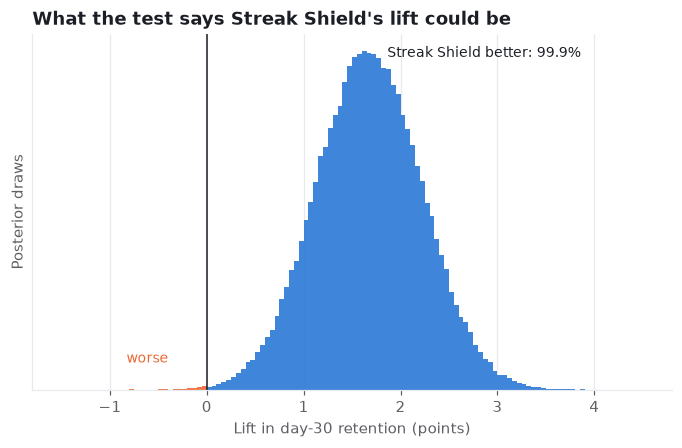

In [7]:
fig, ax = plt.subplots()
bins = np.linspace(-1.5, 4.5, 121)
counts, edges, patches = ax.hist(lift_draws, bins=bins, color=style.SERIES[0], alpha=0.9)
for patch, left in zip(patches, edges[:-1]):
    if left < 0:
        patch.set_facecolor(style.SERIES[1])
ax.axvline(0, color=style.INK, linewidth=1)
ax.annotate(f"Streak Shield better: {cl['chance to win']:.1%}", xy=(np.median(lift_draws), counts.max()),
            xytext=(12, -4), textcoords="offset points", fontsize=9, color=style.INK)
ax.annotate("worse", xy=(-0.3, counts.max() * 0.08), xytext=(-6, 0), textcoords="offset points",
            ha="right", fontsize=9, color=style.SERIES[1])
ax.set(title="What the test says Streak Shield's lift could be",
       xlabel="Lift in day-30 retention (points)", ylabel="Posterior draws")
ax.set_yticks([])
plt.show()

### Chance to win isn't a decision

Chance to win is easy to read, so teams turn it into a rule: ship at 95%. That rule has a flaw. It ignores **how much** you'd lose when you're wrong. An 80% chance to win could hide a 20% chance of a tiny loss, or a 20% chance of a disaster. The two call for different decisions, and chance to win can't tell them apart.

## Reading 3: expected loss

**Expected loss** fixes that. For each posterior draw, ask how much worse off you'd be if you shipped and that draw were the truth. That's zero if Streak Shield is better, and the size of the deficit if it's worse. Then average:

$$
\text{expected loss of shipping} = E\big[\max(-\Delta, 0)\big],
$$

where $\Delta$ is the lift. It's the average regret of the decision, in the metric's own units. For Streak Shield it's **0.0002 points**: if we ship and we're wrong, we're wrong by very little, very rarely.

The decision rule is then: **ship when the expected loss drops below a threshold you'd genuinely not care about.** Some platforms call this the "threshold of caring". Write it down before the test, like the MDE in Chapter 2.

This is where Juno-Lite comes in. Here are both of its numbers side by side: completion, where Lite is built to be slightly worse, and value per lesson, which also counts what each lesson costs to serve.

In [8]:
rows = {}
for metric, scale, unit in [("completion", 100, "points"), ("value", 1000, "$ per 1,000 lessons")]:
    d, s = lite[metric]
    draws = np.random.default_rng(1).normal(d, s, 200_000) * scale
    c = R.chance_and_loss(draws)
    rows[f"{metric} ({unit})"] = {"Lite - Medium": d * scale, "p-value": 2 * stats.norm.sf(abs(d) / s),
                                  "chance Lite wins": c["chance to win"],
                                  "loss if we switch": c["expected loss if we ship"],
                                  "loss if we stay": c["expected loss if we don't"]}
pd.DataFrame(rows).T.style.format({"Lite - Medium": "{:+.2f}", "p-value": "{:.3f}",
                                   "chance Lite wins": "{:.0%}", "loss if we switch": "{:.2f}",
                                   "loss if we stay": "{:.2f}"})

,Lite - Medium,p-value,chance Lite wins,loss if we switch,loss if we stay
completion (points),-1.49,0.393,20%,1.69,0.19
"value ($ per 1,000 lessons)",+2.51,0.152,92%,0.06,2.56


The posterior for value per lesson uses the delta-method standard error from Chapter 2, because the test randomised learners, not lessons. With a flat prior and a large sample, the posterior is simply a normal curve centred on the estimate, with the standard error as its width. That's how most platforms compute chance to win for any metric, not just conversion rates.

In [9]:
glue_num("lite_drop", -100 * lite["completion"][0])
glue_num("lite_comp_p", 2 * stats.norm.sf(abs(lite["completion"][0]) / lite["completion"][1]))
glue_num("lite_comp_lo", 100 * (lite["completion"][0] - 1.96 * lite["completion"][1]))
glue_num("lite_true_gain", 1000 * (R.value_per_lesson(R.LITE) - R.value_per_lesson(R.MEDIUM)))

Read the table as a decision:

- **Completion** drops by about 1.5 points. This test can't confirm it (p = 0.39), though in the simulator Lite really is a slightly weaker tutor.
- **Value** rises, because Lite costs a third as much per lesson. The p-value says "not significant". The expected loss of switching is \$0.06 per 1,000 lessons; the expected loss of staying is \$2.57. Staying is about 43 times riskier than switching.

If Juno's threshold of caring is, say, \$0.50 per 1,000 lessons, the switch clears it easily. Waiting for significance would mean running the test several times longer to protect against a downside worth pennies. (The simulator's true gain is \$2.50 per 1,000, so the switch is in fact right.)

> **Warning**
>
> Expected loss works because value per lesson already prices in the completion drop. If completion has its own guardrail, such as Chapter 2's "no more than 2 points", that guardrail still applies separately, and here it isn't met: the completion interval reaches down to -4.9 points, so this test can't show the drop is under 2. The honest decision is to keep testing until the completion guardrail is settled, or to agree a different margin explicitly. Don't let a money metric quietly override a promise you made to learners.

So which readout should you use?

| Question | Tool | Use it for |
|---|---|---|
| "Is there any effect at all?" | p-value | Controlling false alarms across a platform; scientific claims |
| "How big could it be?" | Confidence or credible interval | Every readout. Always show it |
| "How likely is it better?" | Chance to win | Communicating to non-statisticians |
| "What do I risk by acting?" | Expected loss | Ship decisions, especially cheap and reversible ones |

## The winner's curse

One more trap, and it's the one I see most often in quarterly reviews. Every shipped test's lift gets added up, and the total never shows up in the top-line numbers. Here's why.

Imagine Parlo's last 2,000 experiments. Most changes have small true effects, a fraction of a point either way. Each test measures its lift with noise, a standard error of about 0.7 points (roughly Chapter 1's test size). The team ships the ones that come out significantly positive and records their measured lifts.

In [10]:
truth, est, se_p = R.portfolio()
winners = (est / se_p > 1.96)
prior_mean = est.mean()
prior_sd = np.sqrt(max(est.var() - se_p ** 2, 0))     # spread of TRUE effects, learned from the history
shrunk = R.shrink(est, se_p, prior_mean, prior_sd)
pd.Series({"winners shipped": f"{winners.sum():,}",
           "average reported lift": f"{est[winners].mean():.2f}",
           "average true lift": f"{truth[winners].mean():.2f}",
           "average shrunk estimate": f"{shrunk[winners].mean():.2f}"}).to_frame("winning tests")

,winning tests
winners shipped,200
average reported lift,1.82
average true lift,0.87
average shrunk estimate,0.88


In [11]:
glue_num("wc_rep", est[winners].mean())
glue_num("wc_true", truth[winners].mean())
glue_num("wc_ratio", est[winners].mean() / truth[winners].mean())
glue_num("wc_shrunk", shrunk[winners].mean())
glue_num("wc_prior_sd", prior_sd)
glue_num("wc_weight", 100 * prior_sd ** 2 / (prior_sd ** 2 + se_p ** 2))

The winners reported an average lift of 1.82 points. Their true average was 0.87: the reports were about 2.1 times too big. Gelman and Carlin call this a **type M (magnitude) error** (Gelman and Carlin, 2014). No test was biased on its own. The *selection* was. When the true effect is small relative to the noise, the only way to clear the significance bar is to get lucky, so the tests that clear it are, on average, the lucky ones.

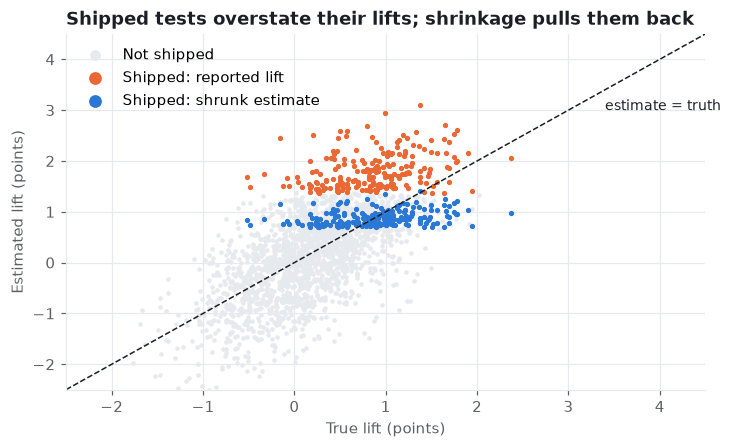

In [12]:
fig, ax = plt.subplots()
ax.scatter(truth[~winners], est[~winners], s=4, color=style.GRID, label="Not shipped")
ax.scatter(truth[winners], est[winners], s=6, color=style.SERIES[1], label="Shipped: reported lift")
ax.scatter(truth[winners], shrunk[winners], s=6, color=style.SERIES[0], label="Shipped: shrunk estimate")
lim = np.array([-2.5, 4.5])
ax.plot(lim, lim, color=style.INK, linewidth=1, linestyle="--")
ax.annotate("estimate = truth", xy=(3.3, 3.3), xytext=(6, -10), textcoords="offset points",
            fontsize=9, color=style.INK)
ax.set(title="Shipped tests overstate their lifts; shrinkage pulls them back",
       xlabel="True lift (points)", ylabel="Estimated lift (points)", xlim=lim, ylim=lim)
ax.legend(loc="upper left", markerscale=3)
plt.show()

The orange dots sit mostly above the dashed line: nearly every shipped test claimed more than it delivered. The fix uses the history itself. The spread of past estimates, minus the noise, tells you how big true effects at Parlo usually are (here, a standard deviation of about 0.6 points). Use that as a prior and each estimate gets pulled towards the typical effect. With this test size the pull keeps only 42% of each estimate's distance from the average. The shrunk estimates (blue) average 0.88, right on the truth. One by one they're still imperfect, since shrinkage can't tell a lucky test from a genuinely great one, but as a total they're honest.

<details>
<summary><b>The shrinkage formula</b></summary>

With a normal prior $\Delta \sim N(\mu, \tau^2)$ for true effects and a normal estimate $\hat\Delta \sim N(\Delta, s^2)$, the posterior mean is

$$
E[\Delta \mid \hat\Delta] = \mu + \frac{\tau^2}{\tau^2 + s^2}\,(\hat\Delta - \mu).
$$

Learning $\mu$ and $\tau$ from past experiments is called **empirical Bayes**. Noisy tests (big $s$) get pulled hard; precise tests barely move. It's the idea behind the informative priors some experimentation platforms let you build from past experiments.

</details>

Two practical lessons. When you **report** a win, report the shrunk number, or at least say the raw one is likely too high. And when you **plan** the next test from a past result ("last time we got 3 points, so size for 3"), you'll undersize it. That's the Chapter 2 mistake again, arriving through the back door.

> **In the wild**
>
> Experimentation teams have a name for the reflex this chapter teaches: **Twyman's law**, "any figure that looks interesting or different is usually wrong". Kohavi, Tang and Xu (Kohavi et al., 2020) give it a whole chapter, with examples of surprising wins at large companies that turned out to be bugs, novelty or luck. The winner's curse is the statistical version of the same law.

## Pitfalls

- **"p = 0.03, so there's a 97% chance it works."** No. That's chance to win, which needs a prior, and it's a different number.
- **"Not significant, so no effect."** Look at the interval. If it runs from slightly negative to large, you've learned little. If it's tight around zero, you've learned a lot.
- **Shipping on chance to win alone.** Price the downside. Expected loss in the metric's own units, or in dollars, is what a decision needs.
- **Peeking at a Bayesian dashboard.** Posteriors make peeking feel safe. Stopping the moment chance to win crosses 95% still inflates mistakes. Chapter 5 covers peeking properly.
- **Adding up shipped lifts.** Winning tests overstate. Shrink before you sum, and confirm with a long-term holdout (Chapter 6).

## Exercises

1. **An informative prior.** Rerun Streak Shield's posterior with a Beta(38, 62) prior on both arms (centred on Parlo's usual retention). Does the chance to win change? Why barely?
2. **A risky winner.** Construct a result with an 85% chance to win but a large expected loss. What does its posterior look like?
3. **Juno's threshold of caring.** Juno serves 2 million lessons a month. Turn the \$0.50 per 1,000 lesson threshold into a monthly amount. Would you set it higher or lower? What would change your mind?
4. **Bigger tests, smaller curse.** In `portfolio`, set `se=0.3`. How does the exaggeration ratio of winners change? What does that say about underpowered tests?

## Further reading

Gelman and Carlin (Gelman and Carlin, 2014) introduce type S and type M errors with clear examples. Kohavi, Tang and Xu (Kohavi et al., 2020) discuss p-value misreadings and how to communicate results.